### Загрузка данных

In [1]:
import pandas as pd

df = pd.read_csv("data/listings.csv")
df = df.sort_values("listing_id", ascending=True)
df.head()

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0


### По каким столбикам будем строить график. Цель - понять, где есть и где нет cлишком больших выбросов

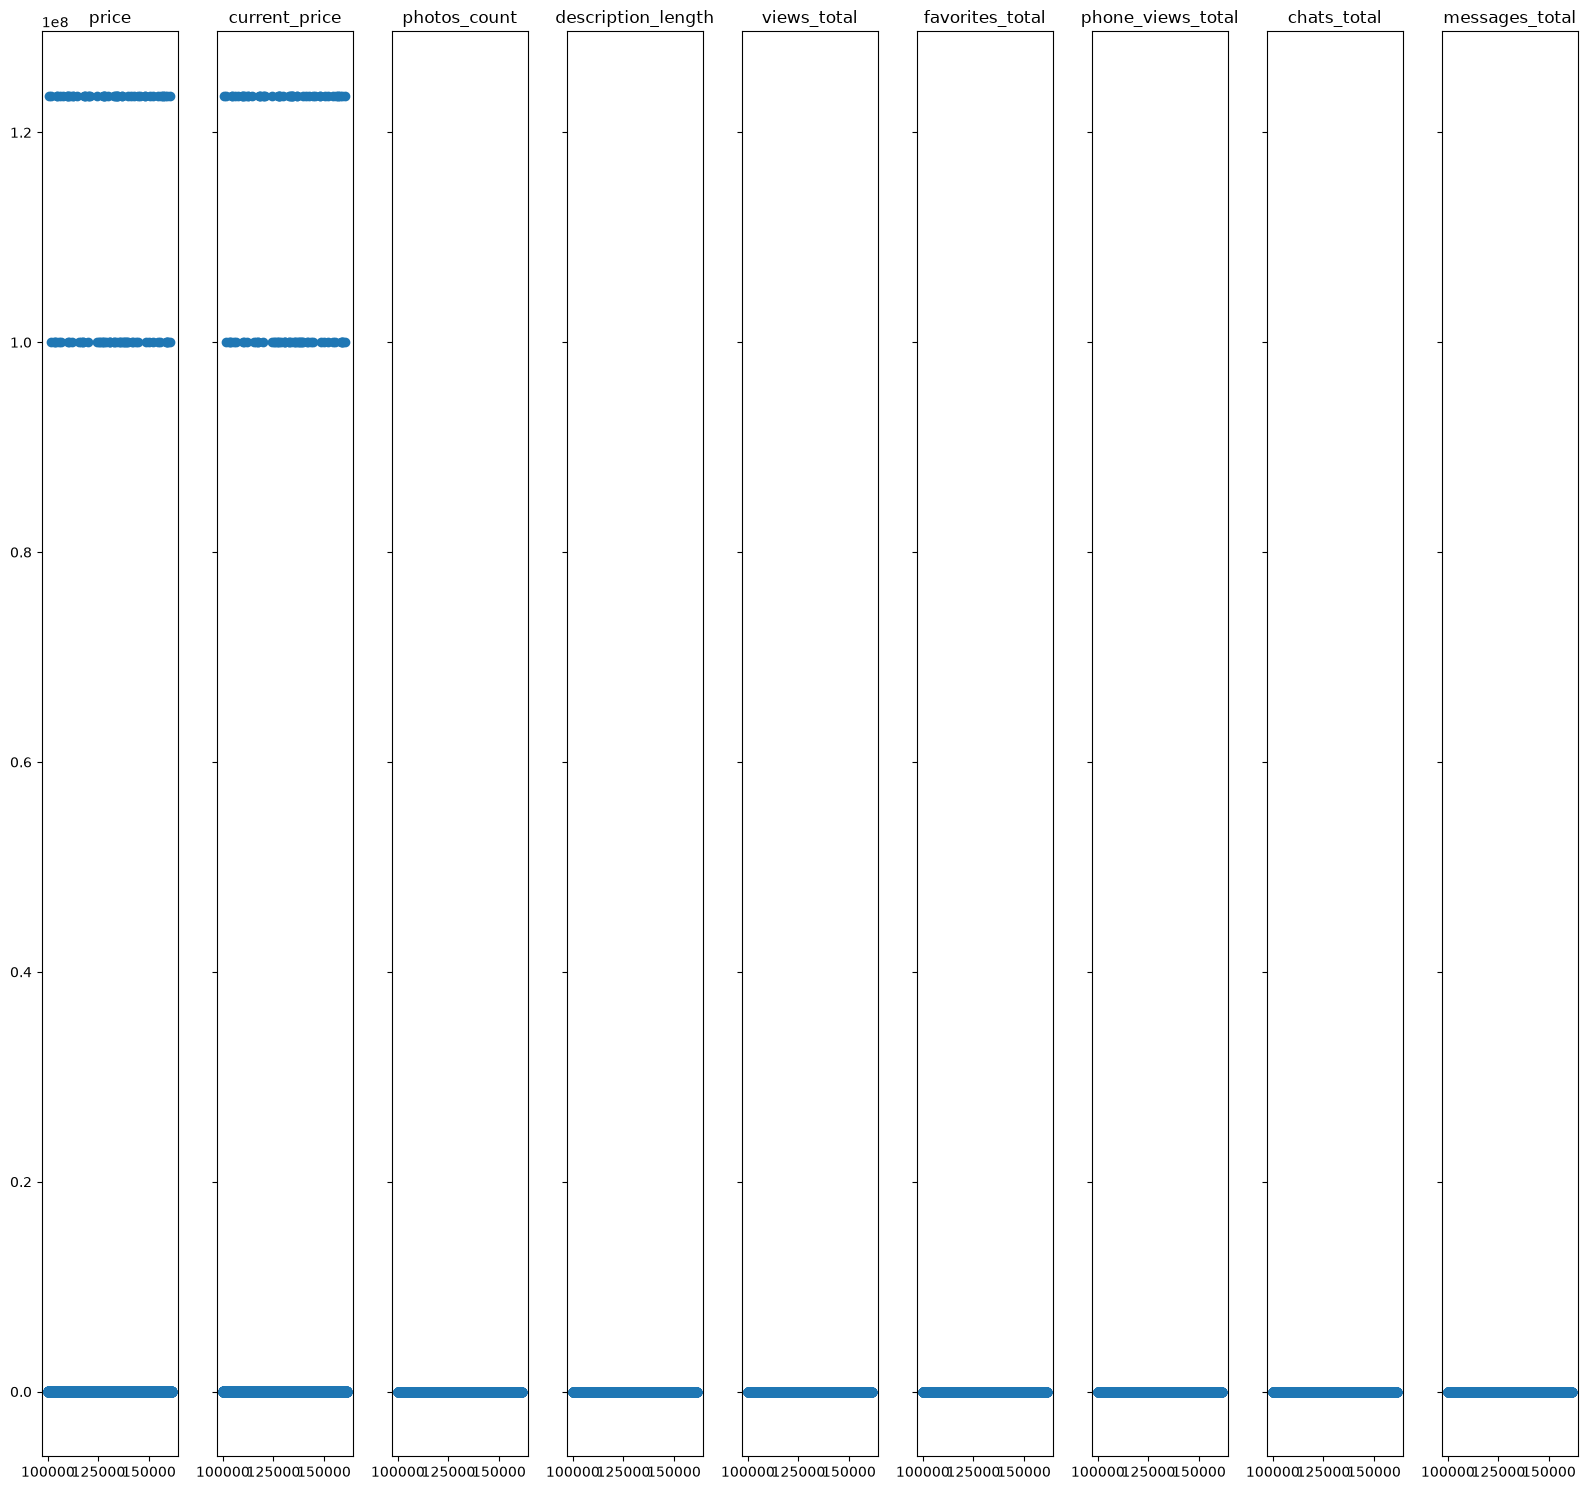

In [2]:
import matplotlib.pyplot as plt

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

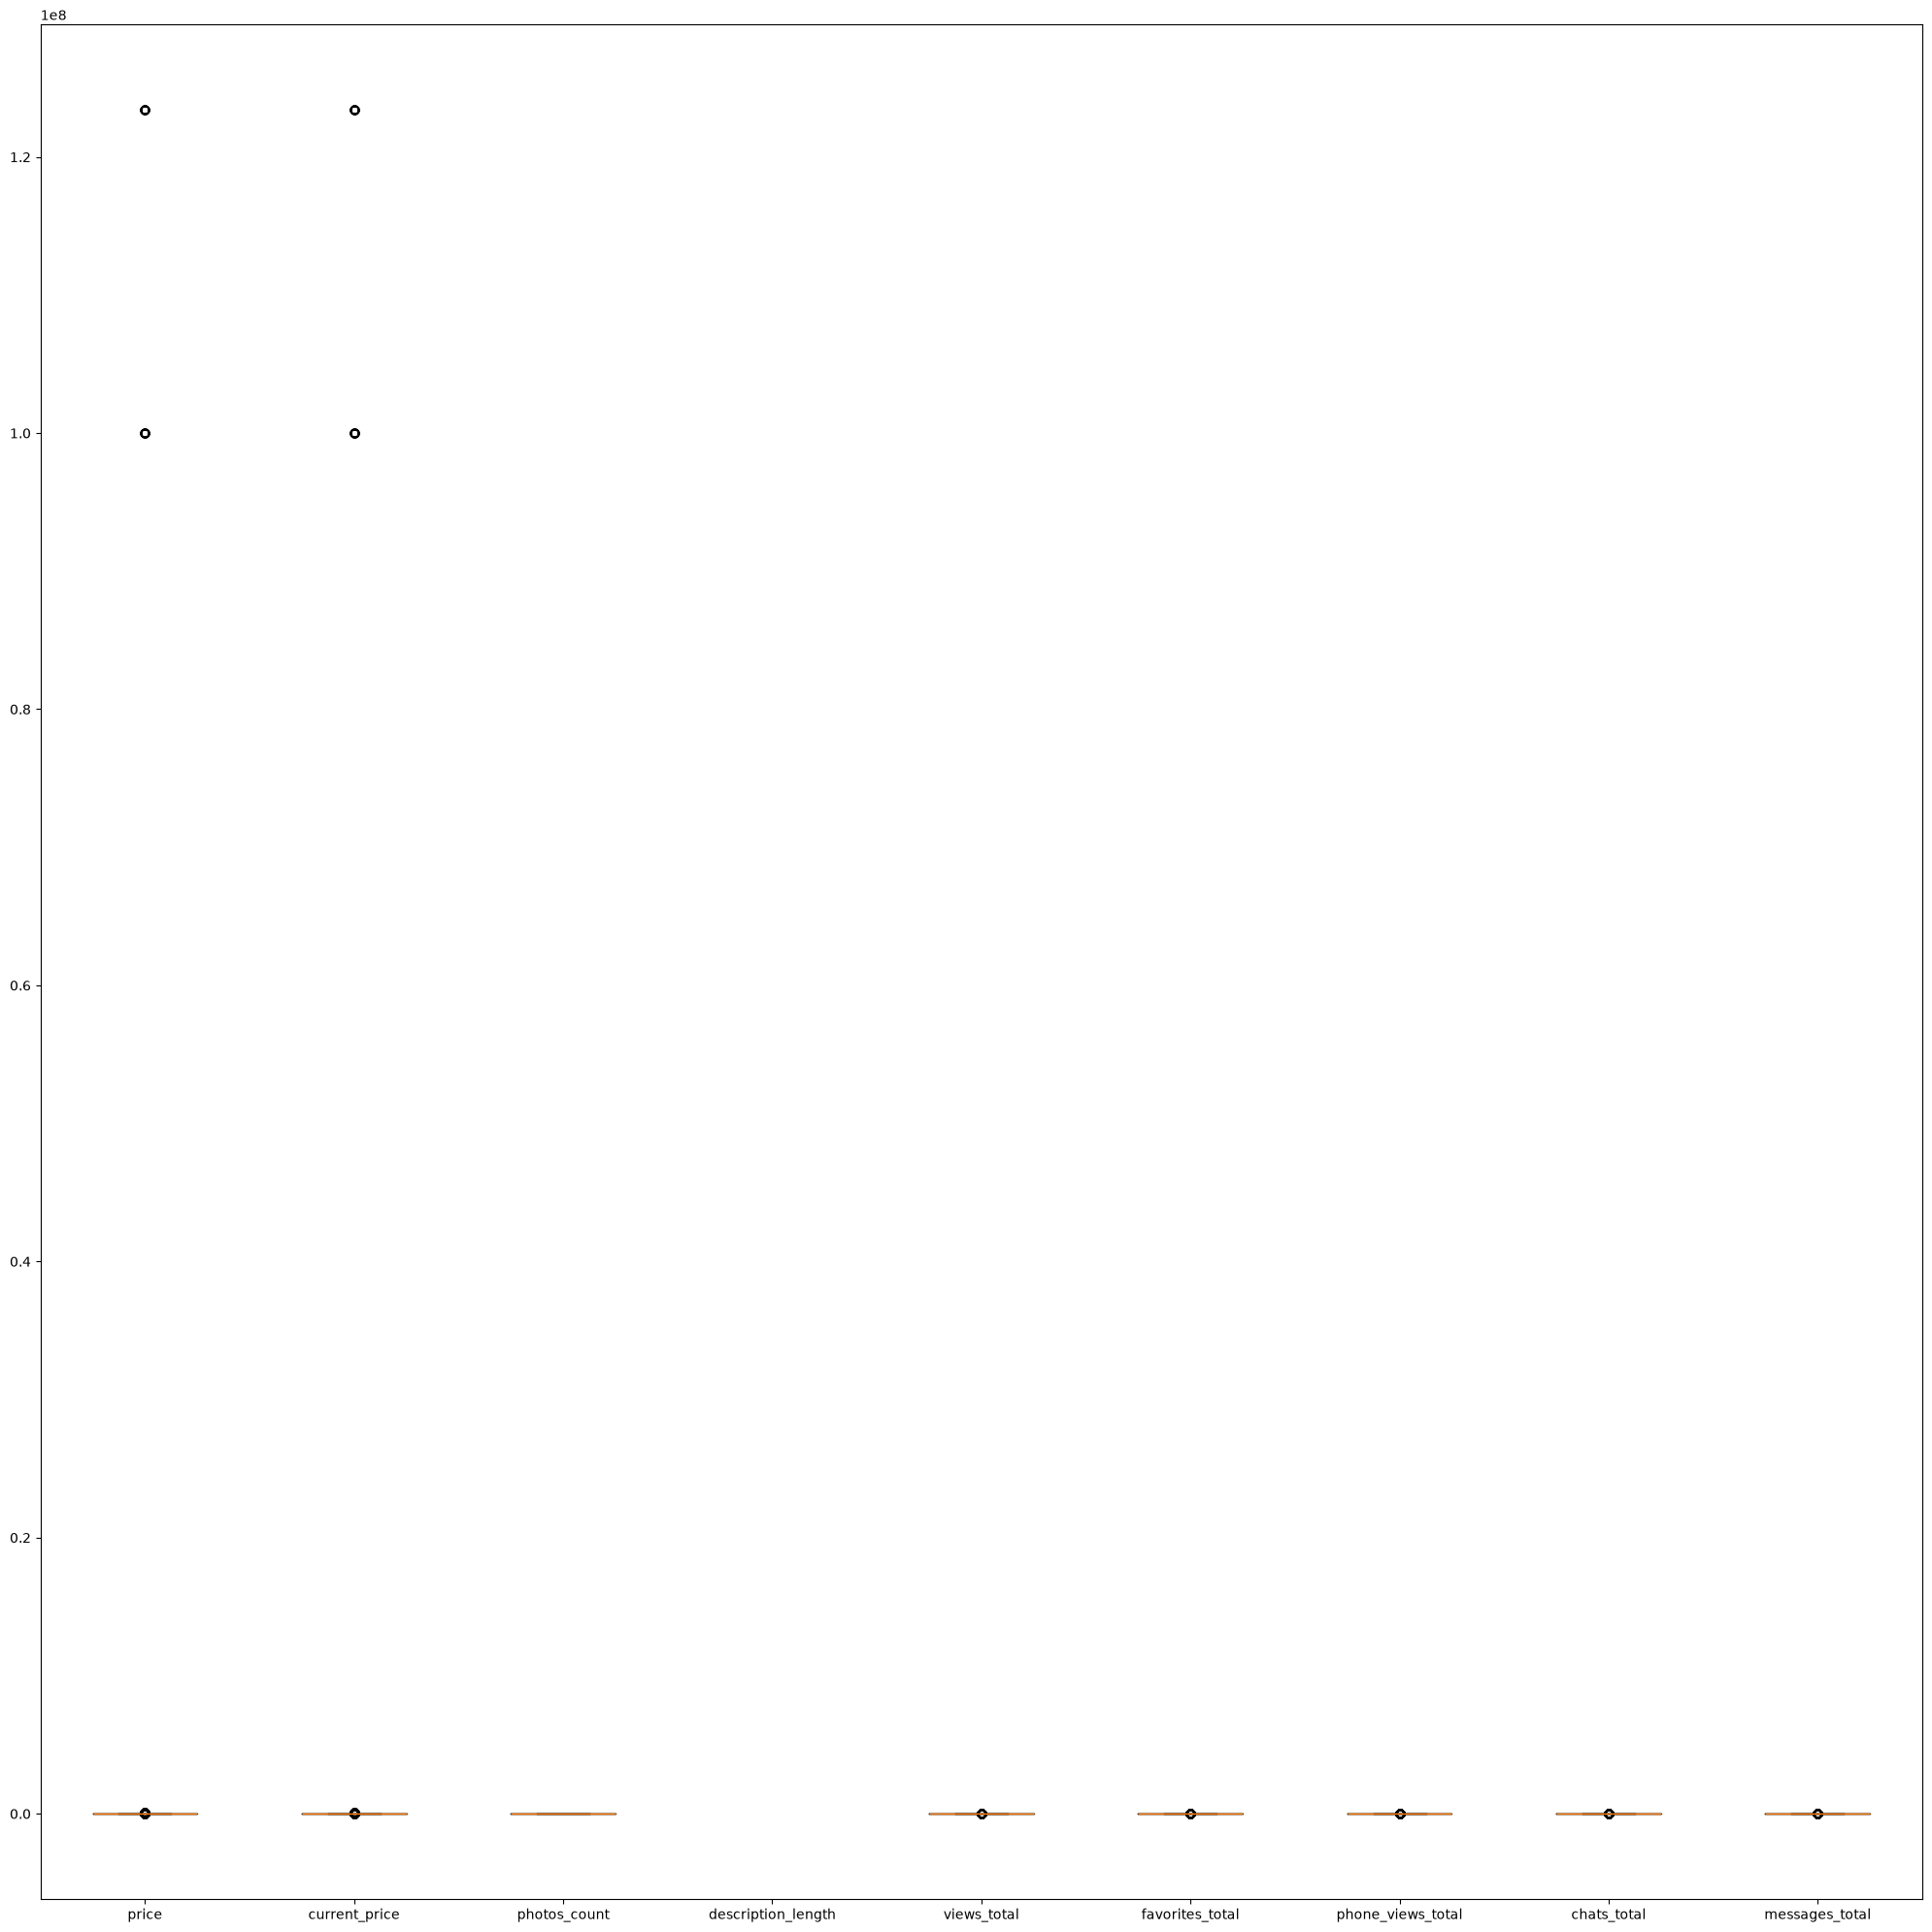

In [3]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 20))
plt.boxplot(data, tick_labels=values)

plt.tight_layout()
plt.show()

In [4]:
df_vibros = df[(df["price"] > 0.2*10**8) | (df["current_price"] > 0.2*10**8)]
display(df_vibros.shape)
#df_vibros.to_csv("vibros.csv", index=False, encoding="utf-8")
df_vibros

(99, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2978,100352,10374,private,Одежда и обувь,Рюкзак городской в хорошем состоянии,123456789,123456789,5,66.0,Новосибирск,2026-08-01 17:40:25,2026-08-06 18:03:07,снято продавцом,55,3,0,1,14
8015,101374,11376,business,Спорт и отдых,Беговая дорожка отличное состояние,123456789,123456789,5,768.0,Санкт-Петербург,2026-08-02 18:30:31,2026-09-01 18:30:31,истёк срок,238,6,0,15,53
5608,101453,11471,private,Электроника,Наушники беспроводные новый,99999999,99999999,5,50.0,Новосибирск,2026-08-02 19:47:31,2026-08-05 17:57:12,снято продавцом,35,1,0,2,23
9551,102833,12850,private,Спорт и отдых,Гантели разборные отличное состояние,99999999,99999999,6,50.0,Санкт-Петербург,2026-08-04 18:20:36,2026-08-08 23:07:37,снято продавцом,36,2,1,0,0
13249,103662,11693,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,99999999,99999999,6,138.0,Москва,2026-08-05 17:59:10,2026-08-06 21:03:57,снято продавцом,25,1,0,2,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1664,158937,32792,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,123456789,123456789,3,53.0,Москва,2026-10-03 23:48:34,2026-10-06 08:18:40,снято продавцом,34,1,0,2,4
3555,159062,40694,private,Спорт и отдых,Беговая дорожка торг,99999999,99999999,3,169.0,Москва,2026-10-04 10:42:05,2026-10-05 19:37:49,снято продавцом,11,0,0,1,8
14069,159591,18365,business,Одежда и обувь,Пальто шерстяное новый,99999999,99999999,7,765.0,Казань,2026-10-04 17:53:52,2026-11-03 17:53:52,истёк срок,248,10,2,10,50
9171,160202,28310,private,Одежда и обувь,Рюкзак городской,99999999,99999999,2,103.0,екатеринбург,2026-10-05 10:16:43,2026-10-11 13:38:14,снято продавцом,60,2,1,2,19


In [5]:
indexes = df_vibros["listing_id"]
display(df.shape)
df = df[~df["listing_id"].isin(indexes)]
display(df.shape)

(15457, 18)

(15358, 18)

In [6]:
med_price = df["price"].median()
med_price_curr = df["current_price"].median()

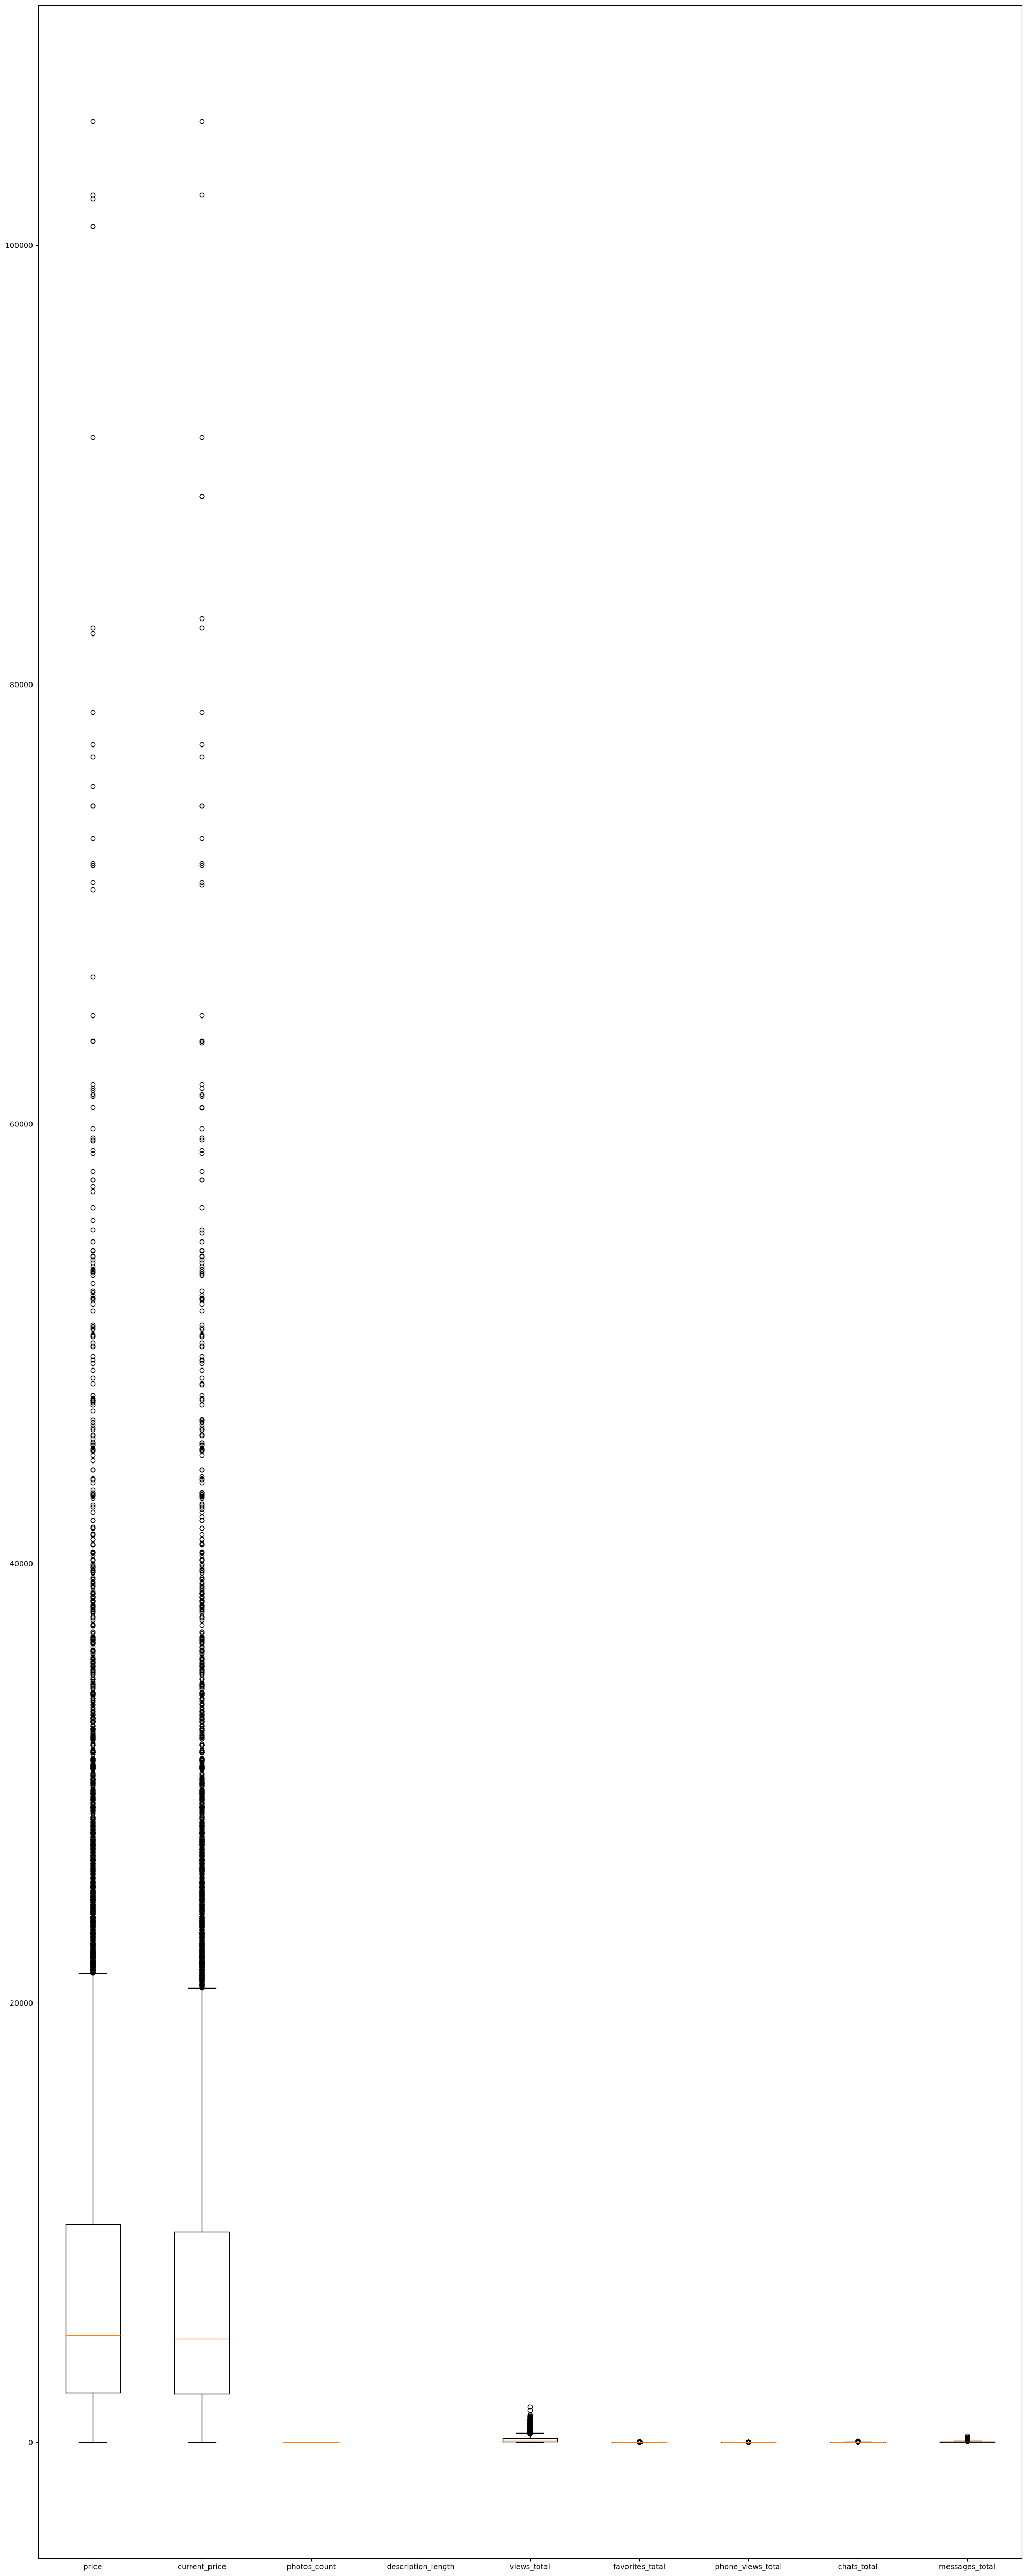

In [7]:
import matplotlib.ticker as ticker

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 50))
plt.boxplot(data, tick_labels=values)

ax.grid(True)
plt.tight_layout()
plt.show()

In [8]:
df_low_med = df[(df["price"] < med_price) | (df["current_price"] < med_price_curr)]
df_low_med_price = df_low_med.sort_values(by="price", ascending=True)
df_low_med_price_curr = df_low_med.sort_values(by="current_price", ascending=True)

In [9]:
df_low_med_price.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
4820,105212,14936,private,Электроника,Ноутбук Lenovo IdeaPad в хорошем состоянии,0,0,7,335.0,Нижний Новгород,2026-08-07 18:44:55,2026-08-09 21:15:46,снято продавцом,127,5,0,4,25
3587,110782,15971,private,Электроника,Колонка JBL новый,0,0,3,89.0,Самара,2026-08-14 10:43:44,2026-08-27 12:16:04,снято продавцом,266,8,4,9,46
11827,152174,10656,business,Бытовая техника,Холодильник Bosch в хорошем состоянии,0,0,8,159.0,Москва,2026-09-27 17:43:11,2026-10-27 17:43:11,истёк срок,430,12,4,18,45
3896,108789,16103,business,Электроника,Колонка JBL,0,0,2,564.0,Москва,2026-08-11 21:56:46,2026-09-10 21:56:46,истёк срок,288,4,3,12,41
1629,137194,33863,private,Запчасти и аксессуары,Шины зимние R16 срочно,0,0,3,72.0,Нижний Новгород,2026-09-12 21:26:04,2026-09-24 07:51:58,снято продавцом,40,1,0,1,17
4338,134076,32714,private,Мебель и интерьер,Стеллаж в хорошем состоянии,0,0,8,77.0,Санкт-Петербург,2026-09-09 22:21:10,2026-10-09 22:21:10,истёк срок,130,6,4,6,21
6272,126118,10870,private,Одежда и обувь,Свитер вязаный,0,0,5,NaN,Санкт-Петербург,2026-09-01 18:38:29,2026-09-11 19:42:58,снято продавцом,129,6,0,6,20
1500,130262,11376,business,Спорт и отдых,Беговая дорожка,0,0,10,1466.0,Санкт-Петербург,2026-09-05 21:29:11,2026-10-05 21:29:11,истёк срок,462,17,10,17,68
7577,124945,28572,private,Бытовая техника,Кондиционер отличное состояние,0,0,4,135.0,Санкт-Петербург,2026-08-31 14:10:40,2026-09-11 20:33:19,снято продавцом,77,1,1,4,25
8335,111237,16005,private,Детские товары,Кроватка детская,0,0,3,238.0,Казань,2026-08-14 19:18:20,2026-08-21 20:03:50,снято продавцом,47,1,1,4,23


In [10]:
df_low_med_price_curr.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
6732,143435,13742,private,Запчасти и аксессуары,Видеорегистратор отличное состояние,0,0,5,114.0,Москва,2026-09-18 19:44:40,2026-09-25 08:54:03,снято продавцом,28,0,2,0,0
2549,143658,36148,private,Электроника,Наушники беспроводные в хорошем состоянии,0,0,3,17.0,Москва,2026-09-18 23:33:28,2026-10-18 23:33:28,истёк срок,205,8,0,10,27
1500,130262,11376,business,Спорт и отдых,Беговая дорожка,0,0,10,1466.0,Санкт-Петербург,2026-09-05 21:29:11,2026-10-05 21:29:11,истёк срок,462,17,10,17,68
12382,119782,14488,private,Мебель и интерьер,Зеркало напольное,0,0,0,135.0,Краснодар,2026-08-24 20:32:06,2026-09-23 20:32:06,истёк срок,230,9,0,9,27
3896,108789,16103,business,Электроника,Колонка JBL,0,0,2,564.0,Москва,2026-08-11 21:56:46,2026-09-10 21:56:46,истёк срок,288,4,3,12,41
919,140657,35158,private,Запчасти и аксессуары,Фара передняя торг,0,0,10,93.0,Москва,2026-09-16 10:06:03,2026-09-25 15:10:47,снято продавцом,53,2,3,0,0
4730,146061,20460,private,Детские товары,Самокат детский,0,0,6,237.0,Краснодар,2026-09-21 17:12:41,2026-09-25 10:55:01,снято продавцом,76,2,0,3,15
11049,107558,17022,private,Электроника,Колонка JBL торг,0,0,5,180.0,Краснодар,2026-08-10 16:27:06,2026-08-14 13:55:20,снято продавцом,57,2,1,3,6
4028,133837,24087,private,Одежда и обувь,Рюкзак городской новый,0,0,4,73.0,Москва,2026-09-09 19:08:03,2026-10-09 19:08:03,истёк срок,244,10,2,11,47
3890,126937,29577,private,Мебель и интерьер,Люстра,0,0,6,17.0,Москва,2026-09-02 16:35:39,2026-09-06 19:46:51,снято продавцом,14,0,0,1,13


In [11]:
df_low = df[(df["price"] < 20) | (df["current_price"] < 20)]
display(df_low.shape)
df_low = df_low.sort_values(by="price", ascending=False)
low_listing_ids = df_low["listing_id"]

(86, 18)

In [16]:
display(df.shape)
df = df[~df["listing_id"].isin(low_listing_ids)]
df

(15272, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5268,161253,22519,business,Одежда и обувь,Пальто шерстяное,1410,1410,6,302.0,Краснодар,2026-10-05 23:39:28,2026-11-04 23:39:28,истёк срок,415,9,1,22,70
8729,161260,13284,private,Одежда и обувь,Костюм мужской,450,410,5,50.0,Екатеринбург,2026-10-05 23:39:59,2026-10-18 22:05:24,снято продавцом,254,5,4,6,19
13486,161261,23053,private,Детские товары,Конструктор LEGO новый,1250,1250,3,94.0,Казань,2026-10-05 23:48:53,2026-10-10 16:32:37,снято продавцом,23,0,1,1,4
14691,161265,25846,private,Бытовая техника,Кофемашина DeLonghi,4530,4530,4,403.0,Москва,2026-10-05 23:56:37,2026-10-12 13:04:41,снято продавцом,28,1,0,1,9


In [19]:
df.to_csv("listins_without_anomailes.csv", index=False, encoding="utf-8")

In [20]:
df_testing = pd.read_csv("listins_without_anomailes.csv")

In [21]:
df_testing = df_testing.sort_values("listing_id", ascending=True)

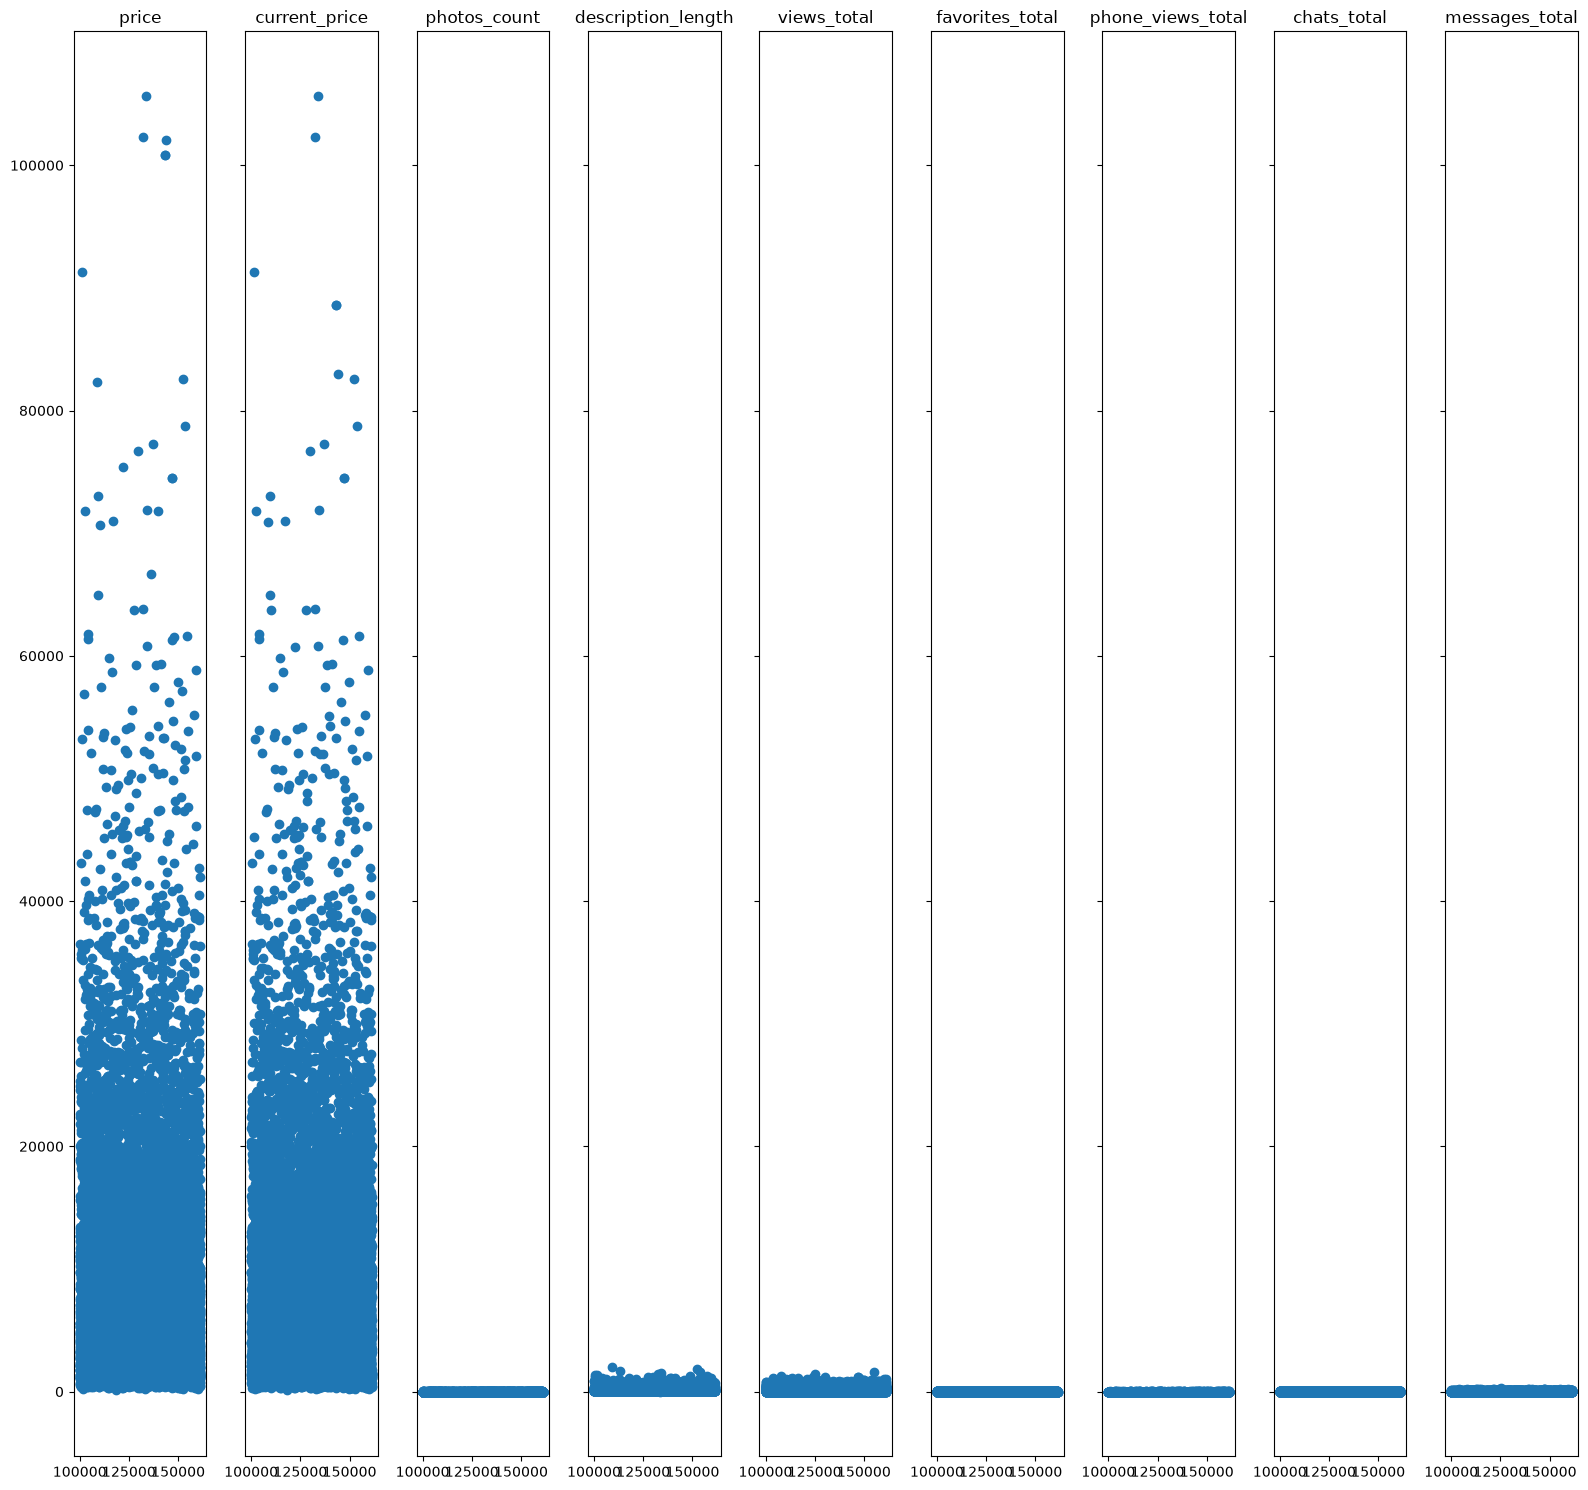

In [22]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()